In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker 

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.preprocessing import PolynomialFeatures

In [3]:
df = pd.read_csv('Position_Salaries.csv')
df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [7]:
# --- Separar en X (independientes) e y (dependiente) ---
# Aquí los datos siguen teniendo nombres legibles en Pandas
X = df.drop(columns=['Salary','Position'])
y = df['Salary']


# --- División en Entrenamiento y Prueba --- No lo hacemos porque el DF es muy pequeño y no es necesario
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1/3, random_state=0)

In [ ]:
Training the linear Regression model on the whole dataset

In [13]:
#Ajustar la regresión lineal con el dataset
lin_regressor = LinearRegression()
lin_regressor.fit(X, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Training the Polynomial Regression model on the whole dataset

In [29]:
#Ajustar la regresión polinómica con el dataset
poly_reg = PolynomialFeatures(degree = 4) #grado del polinómio, por defecto es grado 2 (x2)
X_poly = poly_reg.fit_transform(X) #genera los cuadrados necesarios de la columna X original
lin_reg_2 = LinearRegression()
lin_reg_2.fit(X_poly, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Visualising the Linear Regression results

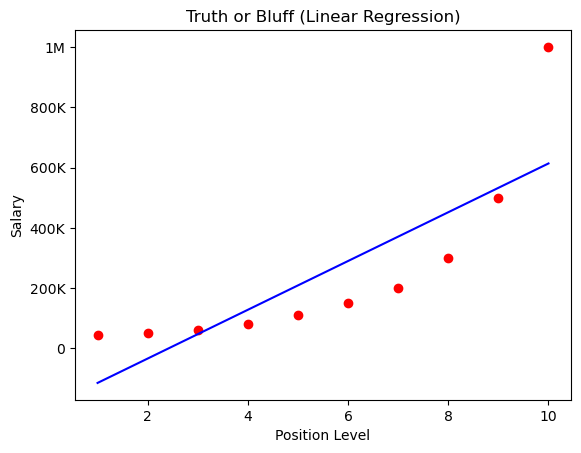

In [27]:
plt.scatter(X, y, color = 'red')
plt.plot(X, lin_regressor.predict(X), color = 'blue')
plt.title('Truth or Bluff (Linear Regression)')
plt.xlabel('Position Level')
plt.ylabel('Salary')

#  Configurar el formato del eje Y para mostrar K y M
def formato_salario(x, pos):
    if x >= 1e6:
        return f'{x*1e-6:.1f}M'.replace('.0M', 'M') # Ejemplo: 1.0M -> 1M
    elif x >= 1e3:
        return f'{x*1e-3:.0f}K'
    return f'{x:.0f}'

#  Aplicar el formateador al eje Y actual
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(formato_salario))
plt.show();

Training the Polynomial Regression model on the whole dataset

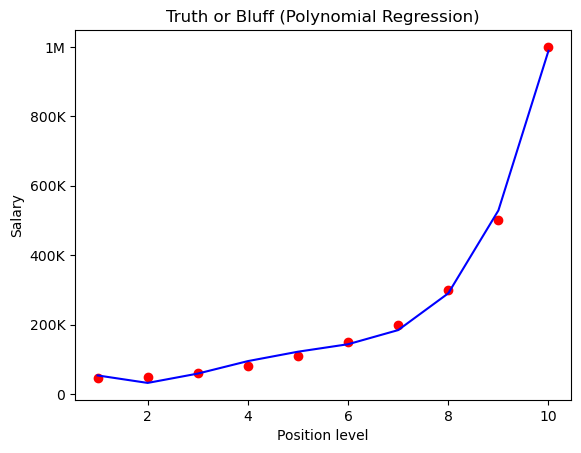

In [30]:
plt.scatter(X, y, color = 'red')
plt.plot(X, lin_reg_2.predict(poly_reg.fit_transform(X)), color = 'blue')
plt.title('Truth or Bluff (Polynomial Regression)')
plt.xlabel('Position level')
plt.ylabel('Salary')

#  Configurar el formato del eje Y para mostrar K y M
def formato_salario(x, pos):
    if x >= 1e6:
        return f'{x*1e-6:.1f}M'.replace('.0M', 'M') # Ejemplo: 1.0M -> 1M
    elif x >= 1e3:
        return f'{x*1e-3:.0f}K'
    return f'{x:.0f}'

#  Aplicar el formateador al eje Y actual
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(formato_salario))
plt.show();

Visualising the Polynomial Regression results (for higher resolution and smoother curve)

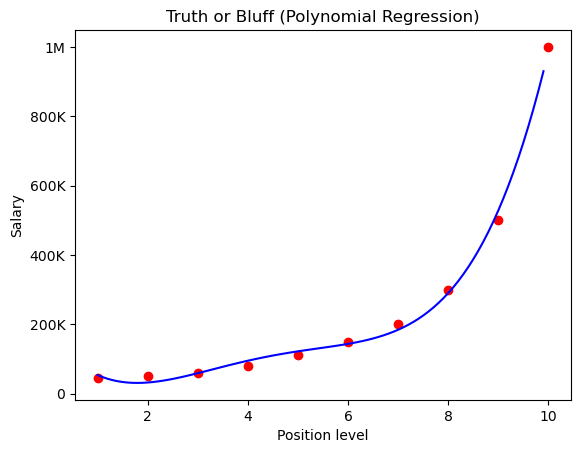

In [25]:
#evitando que queden segmentos lineales entre puntos
X_grid = np.arange(X['Level'].min(), X['Level'].max(), 0.1) #crea secuencia de datos entre min y max con nun número de intervalos
X_grid = X_grid.reshape((len(X_grid), 1)) #redimensionar a vector columna, transponer
plt.scatter(X, y, color = 'red')
plt.plot(X_grid, lin_reg_2.predict(poly_reg.fit_transform(X_grid)), color = 'blue')
plt.title('Truth or Bluff (Polynomial Regression)')
plt.xlabel('Position level')
plt.ylabel('Salary')

#  Configurar el formato del eje Y para mostrar K y M
def formato_salario(x, pos):
    if x >= 1e6:
        return f'{x*1e-6:.1f}M'.replace('.0M', 'M') # Ejemplo: 1.0M -> 1M
    elif x >= 1e3:
        return f'{x*1e-3:.0f}K'
    return f'{x:.0f}'

#  Aplicar el formateador al eje Y actual
plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(formato_salario))
plt.show();

Prediciendo resultados

In [33]:
#Predicting a new result with Linear Regression
lin_regressor.predict([[6.5]])#6.5 level 

C:\Users\G_Ardila\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([330378.78787879])

In [34]:
#Predicting a new result with Polynomial Regression
lin_reg_2.predict(poly_reg.fit_transform([[6.5]]))

array([158862.45265155])